# Card Fraud Triage via Gaussian Mixture Density Scoring and Autoencoder Anomaly Detection

**Objective.** Compare two *unsupervised* anomaly detectors for credit-card fraud:

1. **Gaussian Mixture Model (GMM).** Learns the density of normal transactions. A transaction with a **low log-likelihood** under this density is suspicious.
2. **Autoencoder (AE).** Learns to compress and rebuild normal transactions. A transaction it **reconstructs badly** is suspicious.

Both models are trained **only on legitimate transactions**. Fraud labels are used for only three things:

- choosing between a few autoencoder configurations on the **validation** set;
- choosing an alert threshold on the **validation** set;
- the final evaluation on the **test** set.

**Notebook roadmap**

| Section | What happens |
|---|---|
| A | Load and explore the data |
| B | Prepare features and split the data (no leakage) |
| C | GMM baseline, with the number of components chosen by AIC/BIC |
| D | Autoencoder in PyTorch, with a small training and bottleneck experiment |
| E | Choose thresholds on validation data (1% false-positive budget) |
| F | Evaluate both models on the *same* untouched test set |
| G | Visual trade-offs and interpretation |
| H | Conclusion and limitations |

In [1]:
# ---- Imports ----
import copy
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    precision_score,
    recall_score,
)

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# ---- Reproducibility: fix every random seed we use ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---- Experiment settings (all in one place so they are easy to explain) ----
FPR_BUDGET = 0.01        # we accept flagging at most 1% of legitimate transactions
REVIEW_CAPACITY = 100    # analysts can manually review the top-100 alerts

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1


## A. Introduction and dataset exploration

**Dataset.** *Credit Card Fraud Detection* from the ULB Machine Learning Group:
<https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud>.

- It holds two days of European card transactions from September 2013.
- `V1` to `V28` are anonymised PCA components. The original features are confidential.
- `Time` is the number of seconds since the first transaction in the file.
- `Amount` is the transaction amount.
- `Class` is the label: 1 = fraud, 0 = legitimate.

**How to get it.**

1. Log in to Kaggle.
2. Download the dataset and unzip it.
3. Put `creditcard.csv` in the **same folder as this notebook**.

The loader below also checks the parent folder.

**If you cannot get the dataset**, set `USE_SYNTHETIC_DEMO = True`. The notebook then builds a small *fake* dataset with the same column names, so you can check that every cell runs.
⚠️ Results from synthetic data mean nothing. Never report them as experimental results.

In [2]:
CANDIDATE_PATHS = [Path("creditcard.csv"), Path("../creditcard.csv")]
USE_SYNTHETIC_DEMO = False   # True ONLY to smoke-test the code without the real data

EXPECTED_COLUMNS = ["Time"] + [f"V{i}" for i in range(1, 29)] + ["Amount", "Class"]


def make_synthetic_demo_data(n_rows=20_000, fraud_rate=0.005, seed=SEED):
    # Fake data with the same columns as creditcard.csv. It is only for checking that the code runs.
    rng = np.random.default_rng(seed)
    n_fraud = int(n_rows * fraud_rate)
    n_legit = n_rows - n_fraud
    legit = rng.normal(0, 1, size=(n_legit, 28))
    fraud = rng.normal(1.5, 2.0, size=(n_fraud, 28))   # fraud is shifted and more spread out
    demo = pd.DataFrame(np.vstack([legit, fraud]), columns=[f"V{i}" for i in range(1, 29)])
    demo.insert(0, "Time", rng.uniform(0, 172_800, n_rows))
    demo["Amount"] = rng.lognormal(3, 1.5, n_rows).round(2)
    demo["Class"] = np.r_[np.zeros(n_legit, int), np.ones(n_fraud, int)]
    return demo


data_path = next((p for p in CANDIDATE_PATHS if p.exists()), None)

if USE_SYNTHETIC_DEMO:
    print("⚠️  SYNTHETIC DEMO MODE: the numbers below are NOT real experimental results.")
    df = make_synthetic_demo_data()
elif data_path is None:
    raise FileNotFoundError(
        "creditcard.csv not found. Download it from "
        "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud, unzip it and place "
        "creditcard.csv next to this notebook. (To test the code only, set USE_SYNTHETIC_DEMO = True.)"
    )
else:
    df = pd.read_csv(data_path)
    print(f"Loaded {data_path.resolve()}")

missing_cols = set(EXPECTED_COLUMNS) - set(df.columns)
if missing_cols:
    raise ValueError(f"The CSV is missing expected columns: {sorted(missing_cols)}")

print("Shape (rows, columns):", df.shape)
df.head()

Loaded /Users/yashdhankhar/Desktop/class/creditcard.csv
Shape (rows, columns): (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
print("Columns:", list(df.columns))
print("\nData types:\n", df.dtypes.value_counts())
print("\nMissing values in the whole table:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Data types:
 float64    30
int64       1
Name: count, dtype: int64

Missing values in the whole table: 0
Exact duplicate rows: 1081


Legitimate: 284,315
Fraud:      492  (0.173% of all transactions)


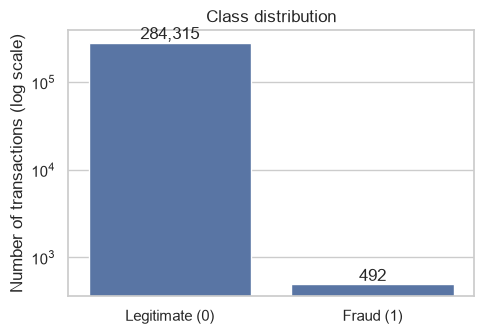

In [4]:
class_counts = df["Class"].value_counts().sort_index()
fraud_count = int(class_counts.get(1, 0))
fraud_pct = 100 * fraud_count / len(df)
print(f"Legitimate: {class_counts[0]:,}")
print(f"Fraud:      {fraud_count:,}  ({fraud_pct:.3f}% of all transactions)")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.barplot(x=["Legitimate (0)", "Fraud (1)"], y=class_counts.values, ax=ax)
ax.set_yscale("log")   # log scale, otherwise the fraud bar is invisible
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution")
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [5]:
# Descriptive statistics. V1..V28 are already centred PCA components; Time and Amount are on raw scales.
df[["Time", "Amount", "V1", "V2", "V3", "V14", "V17", "Class"]].describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
Amount,284807.0,8.834962e+01,250.120109,0.000000,5.600000,22.000000,77.165000,25691.160000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V14,284807.0,1.213481e-15,0.958596,-19.214325,-0.425574,0.050601,0.493150,10.526766
V17,284807.0,-3.768179e-16,0.849337,-25.162799,-0.483748,-0.065676,0.399675,9.253526
Class,284807.0,1.727486e-03,0.041527,0.000000,0.000000,0.000000,0.000000,1.000000


### Why accuracy is misleading here

Fraud is well under 1% of the rows. A useless model that calls *every* transaction legitimate would still score over 99.8% accuracy, and it would catch zero frauds. The next cell computes this.

So we use metrics that focus on the rare fraud class instead:

- precision and recall;
- the precision-recall curve and its area (average precision);
- recall at a fixed false-positive rate;
- precision among the top-K alerts.

In [6]:
always_legit_accuracy = (df["Class"] == 0).mean()
print(f"Accuracy of a model that ALWAYS predicts 'legitimate': {always_legit_accuracy:.4%}")
print("...and it catches 0 frauds (recall = 0).")

Accuracy of a model that ALWAYS predicts 'legitimate': 99.8273%
...and it catches 0 frauds (recall = 0).


## B. Data preparation

These are the decisions we made, so they can be explained in the viva.

1. **Remove exact duplicate rows.** If one copy of a row lands in training and another in test, the test score is inflated. This is a leakage risk.
2. **Exclude `Time`.**
   - `Time` only counts seconds from the start of a two-day file. It describes *when the file started*, not the transaction itself.
   - A density model would learn "normal times in these two days", which would not carry over to new data.
   - Turning it into an hour-of-day feature is listed as a future improvement.
3. **Transform `Amount` with `log1p`.** Amounts are very right-skewed. `log(1 + x)` compresses large values and is safe at 0. It works row by row and learns nothing from the data, so it cannot leak.
4. **Split the data with a random stratified 60/20/20 split.**
   - This is a **random-split experiment**, not a chronological one.
   - The data covers only two days, so a time-based split would give a very small and possibly unrepresentative test period.
   - Stratifying keeps the fraud rate the same in train, validation and test.
5. **Train on legitimate transactions only.**
   - We drop fraud rows from the training split. They are not used anywhere.
   - We set aside 10% of the legitimate training rows as an *early-stopping* set for the autoencoder. This lets the autoencoder stop training without looking at validation fraud labels.
6. **Fit the `StandardScaler` on the legitimate fitting rows only.** We then apply the same fitted scaler to every other split.

| Split | Contents | Used for |
|---|---|---|
| `fit` | legitimate training rows (90%) | fitting the scaler, GMM and AE |
| `es` | legitimate training rows (10%) | AE early stopping only |
| `val` | legitimate + fraud | choosing thresholds |
| `test` | legitimate + fraud | final evaluation, used **once** |

In [7]:
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {n_before - len(df):,} duplicate rows -> {len(df):,} rows remain")
print(f"Fraud rows remaining: {int(df['Class'].sum()):,}")

Removed 1,081 duplicate rows -> 283,726 rows remain
Fraud rows remaining: 473


In [8]:
FEATURE_COLUMNS = [f"V{i}" for i in range(1, 29)] + ["Amount_log"]

# Build the feature table. `Class` is never included. `Time` is deliberately excluded (see above).
X_all = df[[f"V{i}" for i in range(1, 29)]].copy()
X_all["Amount_log"] = np.log1p(df["Amount"])
X_all = X_all[FEATURE_COLUMNS]
y_all = df["Class"].to_numpy()

assert "Class" not in X_all.columns and "Time" not in X_all.columns
print("Number of input features:", X_all.shape[1])

Number of input features: 29


In [9]:
# 60% train / 20% validation / 20% test, stratified by Class
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=SEED  # 0.25 * 0.8 = 0.2
)

# Keep ONLY legitimate transactions for training. Fraud rows in the training split are discarded.
X_train_legit = X_train[y_train == 0]
print(f"Fraud rows dropped from the training split (never used): {int((y_train == 1).sum())}")

# Split the legitimate training rows: 90% to fit the models, 10% for autoencoder early stopping
X_fit, X_es = train_test_split(X_train_legit, test_size=0.10, random_state=SEED)

summary = pd.DataFrame({
    "rows": [len(X_fit), len(X_es), len(X_val), len(X_test)],
    "fraud": [0, 0, int(y_val.sum()), int(y_test.sum())],
}, index=["fit (legit only)", "es (legit only)", "validation", "test"])
summary["fraud %"] = (100 * summary["fraud"] / summary["rows"]).round(3)
summary

Fraud rows dropped from the training split (never used): 284


,rows,fraud,fraud %
fit (legit only),152955,0,0.000
es (legit only),16996,0,0.000
validation,56745,94,0.166
test,56746,95,0.167


In [10]:
# Fit the scaler on the legitimate fitting rows ONLY, then apply that same scaler everywhere
scaler = StandardScaler().fit(X_fit)

X_fit_s = scaler.transform(X_fit)
X_es_s = scaler.transform(X_es)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("Scaled fit-set mean (should be ~0):", X_fit_s.mean().round(4))
print("Scaled fit-set std  (should be ~1):", X_fit_s.std().round(4))

Scaled fit-set mean (should be ~0): -0.0
Scaled fit-set std  (should be ~1): 1.0


## C. Gaussian Mixture Model baseline

**What a GMM assumes.** It models the data as a weighted sum of *K* multivariate Gaussian "blobs". Each blob has its own mean and full covariance matrix. Training uses the EM algorithm and learns:

- where normal transactions are dense;
- how the features vary together.

**Anomaly score.** `score_samples(x)` returns the log-likelihood log p(x).

- Normal-looking transactions have a high log-likelihood.
- Unusual ones have a low log-likelihood.

We flip the sign so that **higher score = more suspicious**:

$$\text{gmm\_score}(x) = -\log p(x)$$

**Difficulties in high dimensions (29 features here).**

- **Many parameters.** One full covariance matrix has 29·30/2 = 435 parameters, so each component adds about 465 parameters in total.
- **Real data is not Gaussian.** Heavy tails and skew are common, so a few Gaussians can only roughly fit the true shape.
- **Distance concentrates.** In many dimensions, distances (and so likelihoods) become less distinct between typical points.

To keep the experiment cheap:

- We compare a small set of K values: 1, 2, 3, 4, 6 and 8.
- We compare them on a 50,000-row random subsample of the fitting set.
- **Selection rule:** choose the K with the **lowest BIC**. BIC penalises extra parameters more strongly than AIC, which suits a model whose parameter count grows fast.

**Covariance regularisation (`reg_covar = 1e-3`).**

- In a first run with scikit-learn's default (`1e-6`), some components *collapsed*. Their covariance log-determinants fell to about −196, meaning they hugged a near-flat slice of the 29-D space formed by groups of very similar legitimate transactions.
- Those components give enormous likelihood spikes, so AIC and BIC kept improving with every extra component and never reached a minimum.
- Adding 0.001 to each covariance diagonal stops this. Each feature has unit variance after scaling, so this is only 0.1% of it.
- We made this choice for numerical stability *before* looking at any test results.

In [11]:
COMPONENT_OPTIONS = [1, 2, 3, 4, 6, 8]
SELECTION_SAMPLE = 50_000
GMM_REG_COVAR = 1e-3   # small value added to covariance diagonals to stop components collapsing

rng = np.random.default_rng(SEED)
sample_idx = rng.choice(len(X_fit_s), size=min(SELECTION_SAMPLE, len(X_fit_s)), replace=False)
X_select = X_fit_s[sample_idx]

ic_rows = []
for k in COMPONENT_OPTIONS:
    gmm_k = GaussianMixture(n_components=k, covariance_type="full", reg_covar=GMM_REG_COVAR,
                            max_iter=200, random_state=SEED)
    gmm_k.fit(X_select)
    ic_rows.append({"components": k, "AIC": gmm_k.aic(X_select), "BIC": gmm_k.bic(X_select),
                    "converged": gmm_k.converged_})
    print(f"K={k}: AIC={ic_rows[-1]['AIC']:.0f}  BIC={ic_rows[-1]['BIC']:.0f}  converged={gmm_k.converged_}")

ic_table = pd.DataFrame(ic_rows)

K=1: AIC=4032850  BIC=4036943  converged=True
K=2: AIC=2228812  BIC=2237006  converged=True
K=3: AIC=2139656  BIC=2151950  converged=True
K=4: AIC=1651352  BIC=1667748  converged=True
K=6: AIC=680663  BIC=705261  converged=True
K=8: AIC=789664  BIC=822465  converged=True


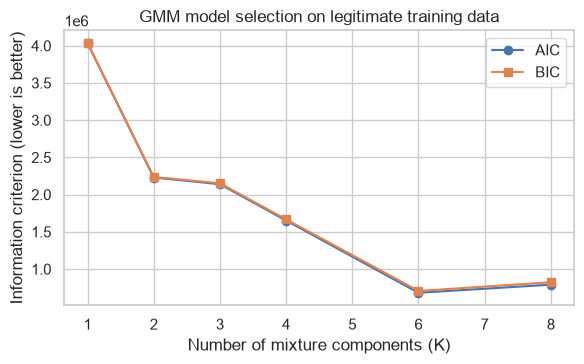

Selected number of components (lowest BIC): K = 6


In [12]:
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(ic_table["components"], ic_table["AIC"], "o-", label="AIC")
ax.plot(ic_table["components"], ic_table["BIC"], "s-", label="BIC")
ax.set_xlabel("Number of mixture components (K)")
ax.set_ylabel("Information criterion (lower is better)")
ax.set_title("GMM model selection on legitimate training data")
ax.legend()
plt.tight_layout()
plt.show()

best_k = int(ic_table.loc[ic_table["BIC"].idxmin(), "components"])
print(f"Selected number of components (lowest BIC): K = {best_k}")
if best_k == max(COMPONENT_OPTIONS):
    print("Note: the lowest BIC is at the largest K we tried. More components might fit even better,")
    print("but we stop here to keep the model small and fast. This is a documented limitation.")

In [13]:
# Refit the chosen GMM on ALL legitimate fitting rows
gmm = GaussianMixture(n_components=best_k, covariance_type="full", reg_covar=GMM_REG_COVAR,
                      max_iter=300, random_state=SEED)
gmm.fit(X_fit_s)
print("Converged:", gmm.converged_, "| EM iterations:", gmm.n_iter_)

# Anomaly score = NEGATIVE log-likelihood -> higher means more suspicious
gmm_val_scores = -gmm.score_samples(X_val_s)
gmm_test_scores = -gmm.score_samples(X_test_s)

print("Mean GMM score, validation legit:", gmm_val_scores[y_val == 0].mean().round(2))
print("Mean GMM score, validation fraud:", gmm_val_scores[y_val == 1].mean().round(2))

Converged: True | EM iterations: 27
Mean GMM score, validation legit: 8.62
Mean GMM score, validation fraud: 465.24


## D. Autoencoder

An **undercomplete autoencoder** squeezes each 29-number transaction through a narrow **bottleneck**, then tries to rebuild the original.

- The bottleneck is smaller than the input, so the network must learn the *typical patterns* of legitimate transactions.
- When a fraud transaction does not follow those patterns, it tends to be rebuilt poorly.

```
input (29) -> Linear 29->16 -> ReLU -> Linear 16->b (bottleneck)      [encoder]
           -> Linear b->16 -> ReLU -> Linear 16->29 -> output (29)      [decoder]
```

- **Loss:** mean squared error (MSE) between the input and its reconstruction.
- **Optimiser:** Adam, learning rate 1e-3, batch size 512.
- **Stopping:** early stopping judged on the *legitimate-only* `es` set, so no fraud labels are involved. The weights from the best epoch are restored at the end.
- **Anomaly score:** per-transaction MSE across the 29 features. **Higher = more suspicious.**

### Autoencoder experiments

The original version (the **baseline**) used bottleneck b = 8, at most 50 epochs and patience 5. Its early-stopping loss was still falling when it hit the 50-epoch cap. We therefore ran two small, controlled experiments:

| Name | Bottleneck b | Max epochs | Patience | Purpose |
|---|---|---|---|---|
| `AE-base` | 8 | 50 | 5 | The original baseline, re-run with identical code |
| `AE-b8` | 8 | 100 | 8 | **Experiment A:** does longer training help? |
| `AE-b4` | 4 | 100 | 8 | **Experiment B:** a smaller bottleneck |
| `AE-b12` | 12 | 100 | 8 | **Experiment B:** a larger bottleneck |

`AE-b8` is both the Experiment A model and the b = 8 point of Experiment B.

**Kept the same in every run:**

- the data split and the scaled features;
- the hidden layer size (16), the optimiser, the learning rate (1e-3) and the batch size (512);
- the seed. The same seed is used for the initial weights and for the batch order in every run.

**How the final configuration is chosen.**

- The network itself is still trained **only on legitimate transactions**.
- To *choose between* the four trained networks, we use the **validation fraud labels**: the configuration with the highest **validation average precision** wins. This is hyperparameter selection on validation data, the same kind of label use as threshold selection in Section E.
- The test set is **not** used for this choice.
- A lower reconstruction loss is *not* used as the selection rule. Rebuilding legitimate transactions better does not automatically mean ranking fraud better.

In [14]:
class Autoencoder(nn.Module):
    def __init__(self, n_features, hidden=16, bottleneck=8):
        super().__init__()
        # Encoder: compress the input down to the bottleneck
        self.encoder = nn.Sequential(
            nn.Linear(n_features, hidden),
            nn.ReLU(),
            nn.Linear(hidden, bottleneck),
        )
        # Decoder: rebuild the input from the bottleneck.
        # There is no activation at the end, because standardised features can be negative.
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck, hidden),
            nn.ReLU(),
            nn.Linear(hidden, n_features),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))


def reconstruction_error(model, X_scaled):
    # Mean squared error per transaction (one number per row). Higher = more suspicious.
    model.eval()
    with torch.no_grad():
        x = torch.tensor(X_scaled, dtype=torch.float32)
        return ((model(x) - x) ** 2).mean(dim=1).numpy()


BATCH_SIZE = 512
LEARNING_RATE = 1e-3

# Tensors for training (legit only) and early stopping (legit only)
fit_tensor = torch.tensor(X_fit_s, dtype=torch.float32)
es_tensor = torch.tensor(X_es_s, dtype=torch.float32)
loss_fn = nn.MSELoss()


def train_autoencoder(bottleneck, max_epochs, patience):
    # Train one autoencoder on LEGIT rows only, with early stopping on the LEGIT `es` rows.
    torch.manual_seed(SEED)   # same initial-weight seed for every configuration
    model = Autoencoder(n_features=X_fit_s.shape[1], bottleneck=bottleneck)
    # A seeded generator makes the batch shuffling order reproducible
    loader = DataLoader(TensorDataset(fit_tensor), batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"train_loss": [], "es_loss": []}
    best_es_loss, best_epoch, best_state = float("inf"), 0, None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        # ---- Training pass: update the weights batch by batch ----
        model.train()
        running_loss = 0.0
        for (batch,) in loader:
            optimizer.zero_grad()                    # clear the gradients from the previous step
            reconstruction = model(batch)            # forward pass
            loss = loss_fn(reconstruction, batch)    # how far is the output from the input?
            loss.backward()                          # backpropagation: compute the gradients
            optimizer.step()                         # move the weights a small step downhill
            running_loss += loss.item() * len(batch)
        history["train_loss"].append(running_loss / len(fit_tensor))

        # ---- Early-stopping check on held-out LEGIT rows (no gradient updates) ----
        model.eval()
        with torch.no_grad():
            es_loss = loss_fn(model(es_tensor), es_tensor).item()
        history["es_loss"].append(es_loss)

        if es_loss < best_es_loss - 1e-5:
            best_es_loss, best_epoch = es_loss, epoch
            best_state = copy.deepcopy(model.state_dict())   # remember the best weights so far
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            break

    model.load_state_dict(best_state)   # go back to the best epoch
    info = {
        "best_es_loss": best_es_loss,
        "best_epoch": best_epoch,
        "epochs_run": len(history["es_loss"]),
        "stopped_by": "early stopping" if epochs_without_improvement >= patience else "epoch cap",
    }
    return model, history, info


print(Autoencoder(n_features=X_fit_s.shape[1]))

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=29, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=29, bias=True)
  )
)


In [15]:
AE_CONFIGS = {
    "AE-base": {"bottleneck": 8, "max_epochs": 50, "patience": 5},    # original baseline
    "AE-b8": {"bottleneck": 8, "max_epochs": 100, "patience": 8},     # Experiment A (and B, b=8)
    "AE-b4": {"bottleneck": 4, "max_epochs": 100, "patience": 8},     # Experiment B
    "AE-b12": {"bottleneck": 12, "max_epochs": 100, "patience": 8},   # Experiment B
}

ae_models, ae_histories, ae_rows = {}, {}, []
for name, cfg in AE_CONFIGS.items():
    model, history, info = train_autoencoder(**cfg)
    val_scores = reconstruction_error(model, X_val_s)
    ae_models[name], ae_histories[name] = model, history
    ae_rows.append({
        "config": name, **cfg,
        "parameters": sum(p.numel() for p in model.parameters()),
        **info,
        # Validation fraud labels are used ONLY here, to compare configurations
        "val_AP": average_precision_score(y_val, val_scores),
    })
    print(f"{name}: best early-stop MSE {info['best_es_loss']:.4f} at epoch {info['best_epoch']} "
          f"({info['epochs_run']} epochs run, stopped by {info['stopped_by']}) | val AP {ae_rows[-1]['val_AP']:.4f}")

ae_experiments = pd.DataFrame(ae_rows).set_index("config")
ae_experiments.round(4)

AE-base: best early-stop MSE 0.4353 at epoch 49 (50 epochs run, stopped by epoch cap) | val AP 0.4049
AE-b8: best early-stop MSE 0.4256 at epoch 99 (100 epochs run, stopped by epoch cap) | val AP 0.4126
AE-b4: best early-stop MSE 0.5055 at epoch 100 (100 epochs run, stopped by epoch cap) | val AP 0.3772
AE-b12: best early-stop MSE 0.4023 at epoch 65 (73 epochs run, stopped by early stopping) | val AP 0.2822


,bottleneck,max_epochs,patience,parameters,best_es_loss,best_epoch,epochs_run,stopped_by,val_AP
config,,,,,,,,,
AE-base,8,50,5,1253,0.4353,49,50,epoch cap,0.4049
AE-b8,8,100,8,1253,0.4256,99,100,epoch cap,0.4126
AE-b4,4,100,8,1121,0.5055,100,100,epoch cap,0.3772
AE-b12,12,100,8,1385,0.4023,65,73,early stopping,0.2822


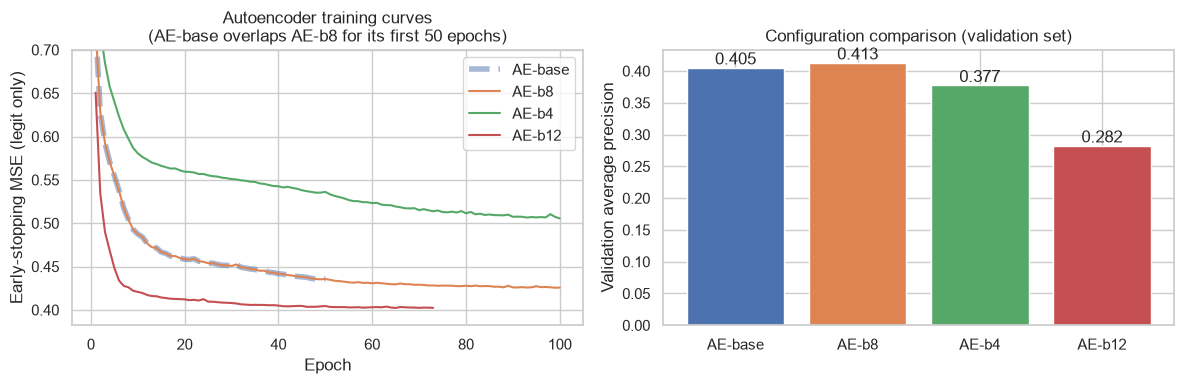

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, history in ae_histories.items():
    # AE-base is drawn wide and dashed: for its 50 epochs it is identical to AE-b8 (same seed and settings)
    style = {"ls": "--", "lw": 4, "alpha": 0.5, "zorder": 1} if name == "AE-base" else {"zorder": 2}
    axes[0].plot(range(1, len(history["es_loss"]) + 1), history["es_loss"], label=name, **style)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Early-stopping MSE (legit only)")
axes[0].set_title("Autoencoder training curves\n(AE-base overlaps AE-b8 for its first 50 epochs)")
axes[0].set_ylim(top=0.7)
axes[0].legend()

axes[1].bar(ae_experiments.index, ae_experiments["val_AP"], color=sns.color_palette()[:len(ae_experiments)])
for i, v in enumerate(ae_experiments["val_AP"]):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom")
axes[1].set_ylabel("Validation average precision")
axes[1].set_title("Configuration comparison (validation set)")
plt.tight_layout()
plt.show()

In [17]:
# Experiment A: does longer training (100 epochs, patience 8) beat the 50-epoch baseline on VALIDATION?
base_ap, longer_ap = ae_experiments.loc["AE-base", "val_AP"], ae_experiments.loc["AE-b8", "val_AP"]
print(f"Experiment A - validation AP: baseline {base_ap:.4f} -> longer training {longer_ap:.4f} "
      f"(change {longer_ap - base_ap:+.4f})")

# Final choice: highest validation AP among all four trained configurations (the test set is not used)
selected_name = ae_experiments["val_AP"].idxmax()
print(f"Selected autoencoder configuration (highest validation AP): {selected_name} "
      f"-> {AE_CONFIGS[selected_name]}")

ae = ae_models[selected_name]
ae_base = ae_models["AE-base"]
ae_val_scores = reconstruction_error(ae, X_val_s)
ae_base_val_scores = reconstruction_error(ae_base, X_val_s)

print("Mean selected-AE score, validation legit:", ae_val_scores[y_val == 0].mean().round(3))
print("Mean selected-AE score, validation fraud:", ae_val_scores[y_val == 1].mean().round(3))

Experiment A - validation AP: baseline 0.4049 -> longer training 0.4126 (change +0.0078)
Selected autoencoder configuration (highest validation AP): AE-b8 -> {'bottleneck': 8, 'max_epochs': 100, 'patience': 8}
Mean selected-AE score, validation legit: 0.432
Mean selected-AE score, validation fraud: 21.646


## E. Threshold selection (validation data only)

The stages are kept strictly apart:

| Stage | Data | Labels used? |
|---|---|---|
| Model training | `fit` / `es` (legit only) | No. Only the decision to drop fraud rows. |
| AE configuration choice (Section D) | `val` | Yes, the validation labels, to compare validation AP |
| Threshold selection | `val` | Yes, the validation labels |
| Final evaluation | `test` | Yes, but **only to measure**, never to tune |

**Rule: a false-positive-rate budget of 1%.**

- Each model's threshold is the 99th percentile of its anomaly scores on *legitimate validation* transactions.
- A transaction is flagged when `score > threshold`.
- This gives a validation FPR of at most 1%.
- Every model uses the same score direction (higher = more suspicious) and the same decision rule.

We keep three models from here on:

- the GMM, which is the reference;
- the **original baseline AE**, so it can still be compared;
- the **selected AE**.

In [18]:
def threshold_for_fpr(legit_scores, fpr_budget):
    # Score above which only `fpr_budget` of legitimate transactions lie.
    return np.quantile(legit_scores, 1 - fpr_budget)


def metrics_at_threshold(y_true, scores, threshold):
    # Decision rule (the same for all models): flag the transaction if score > threshold
    y_pred = (scores > threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "threshold": threshold,
        "flagged": int(tp + fp),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "FPR": fp / (fp + tn),
    }


SELECTED_LABEL = f"AE selected ({selected_name})"
BASE_LABEL = "AE baseline (AE-base)"
val_scores = {"GMM": gmm_val_scores, BASE_LABEL: ae_base_val_scores, SELECTED_LABEL: ae_val_scores}
thresholds = {name: threshold_for_fpr(s[y_val == 0], FPR_BUDGET) for name, s in val_scores.items()}

# One row per model, one column per metric
val_results = pd.DataFrame(
    [metrics_at_threshold(y_val, s, thresholds[name]) for name, s in val_scores.items()],
    index=list(val_scores),
)
val_results["val_AP"] = [average_precision_score(y_val, s) for s in val_scores.values()]
print("VALIDATION results at the chosen thresholds (these numbers were used to SET the thresholds):")
val_results.round(4)

VALIDATION results at the chosen thresholds (these numbers were used to SET the thresholds):


,threshold,flagged,TP,FP,FN,TN,precision,recall,FPR,val_AP
GMM,57.5098,648,81,567,13,56084,0.1250,0.8617,0.01,0.5525
AE baseline (AE-base),1.9348,646,79,567,15,56084,0.1223,0.8404,0.01,0.4049
AE selected (AE-b8),1.8553,647,80,567,14,56084,0.1236,0.8511,0.01,0.4126


## F. Final evaluation on the held-out test set

All three models score **exactly the same test rows** (`X_test_s`). We report the metrics below.

**Threshold-free metrics** (they summarise the whole ranking):

- **Average precision (AP), our PR-AUC.** We use scikit-learn's `average_precision_score`: AP = Σₙ (Rₙ − Rₙ₋₁) · Pₙ. This is a step-wise sum over thresholds, *not* the trapezoidal area, which can be over-optimistic. A random ranking gets an AP equal to the fraud rate.
- **Recall @ 1% FPR (test ROC).** The best recall reachable while flagging at most 1% of legitimate *test* transactions. It is read off the **test** ROC curve, so its cut-off is effectively chosen *using the test labels*. It measures ranking quality and **could not be achieved in practice**, because a real system never knows the test labels in advance.
- **Precision@100.** The fraction of fraud among the 100 highest-scoring test transactions. It describes a team that can review 100 alerts.

**Operational metrics at the validation-chosen threshold:**

- **Recall @ val threshold**, together with precision, FPR, the number flagged and the confusion matrix.
- The threshold was fixed on validation data *before* we looked at the test set, so these show what would *actually* happen if that threshold were deployed.

⚠️ The two recall numbers are **different measurements**. They can coincide by chance, but they should not be treated as interchangeable.

In [19]:
def recall_at_fpr(y_true, scores, fpr_budget):
    # Highest recall (TPR) on the ROC curve with FPR <= budget (cut-off derived from the TEST labels)
    fpr, tpr, _ = roc_curve(y_true, scores)
    return tpr[fpr <= fpr_budget].max()


def precision_at_k(y_true, scores, k):
    # Fraction of fraud among the k highest-scoring transactions
    top_k = np.argsort(-scores, kind="stable")[:k]
    return y_true[top_k].mean()


# Test scores are computed only now, after every choice has been fixed on validation data
ae_test_scores = reconstruction_error(ae, X_test_s)
ae_base_test_scores = reconstruction_error(ae_base, X_test_s)
test_scores = {"GMM": gmm_test_scores, BASE_LABEL: ae_base_test_scores, SELECTED_LABEL: ae_test_scores}
assert all(len(s) == len(y_test) for s in test_scores.values())   # identical test rows for all models

k_review = min(REVIEW_CAPACITY, len(y_test))
rows = {}
for name, scores in test_scores.items():
    at_thr = metrics_at_threshold(y_test, scores, thresholds[name])
    assert at_thr["TP"] + at_thr["FN"] == y_test.sum()          # every test fraud is counted once
    rows[name] = {
        "Average precision (PR-AUC)": average_precision_score(y_test, scores),
        f"Recall @ {FPR_BUDGET:.0%} FPR (test ROC)": recall_at_fpr(y_test, scores, FPR_BUDGET),
        f"Precision @ top-{k_review}": precision_at_k(y_test, scores, k_review),
        "Val-chosen threshold": at_thr["threshold"],
        "Flagged (test)": at_thr["flagged"],
        "Precision @ val threshold": at_thr["precision"],
        "Recall @ val threshold": at_thr["recall"],
        "FPR @ val threshold": at_thr["FPR"],
        "TP": at_thr["TP"], "FP": at_thr["FP"], "FN": at_thr["FN"], "TN": at_thr["TN"],
    }

# One row per model, one column per metric (counts stay integers)
comparison = pd.DataFrame.from_dict(rows, orient="index")
print(f"Test set: {len(y_test):,} transactions, {int(y_test.sum())} fraud "
      f"-> random-ranking AP baseline = {y_test.mean():.4f}")
comparison.round(4)

Test set: 56,746 transactions, 95 fraud -> random-ranking AP baseline = 0.0017


,Average precision (PR-AUC),Recall @ 1% FPR (test ROC),Precision @ top-100,Val-chosen threshold,Flagged (test),Precision @ val threshold,Recall @ val threshold,FPR @ val threshold,TP,FP,FN,TN
GMM,0.4734,0.7789,0.49,57.5098,694,0.1066,0.7789,0.0109,74,620,21,56031
AE baseline (AE-base),0.3568,0.7789,0.41,1.9348,663,0.1116,0.7789,0.0104,74,589,21,56062
AE selected (AE-b8),0.3575,0.7789,0.41,1.8553,667,0.1109,0.7789,0.0105,74,593,21,56058


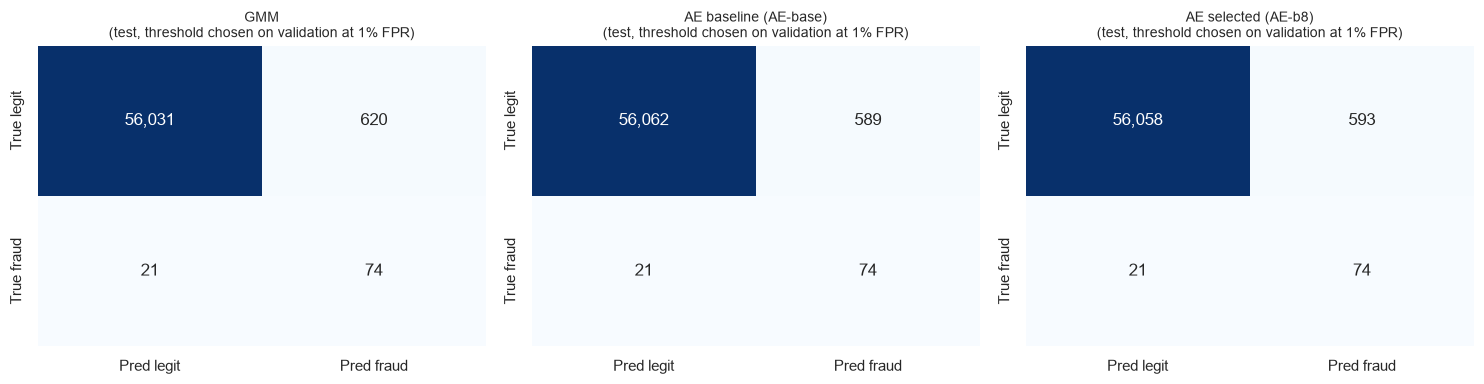

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, test_scores):
    y_pred = (test_scores[name] > thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred legit", "Pred fraud"], yticklabels=["True legit", "True fraud"])
    ax.set_title(f"{name}\n(test, threshold chosen on validation at {FPR_BUDGET:.0%} FPR)", fontsize=10)
plt.tight_layout()
plt.show()

## G. Visualisations and interpretation

### Precision-recall curves

Each curve shows the precision obtained at every possible recall level.

- The dashed line is a random ranking, which sits at the fraud rate.
- The baseline AE is drawn as a thin dotted line for reference.

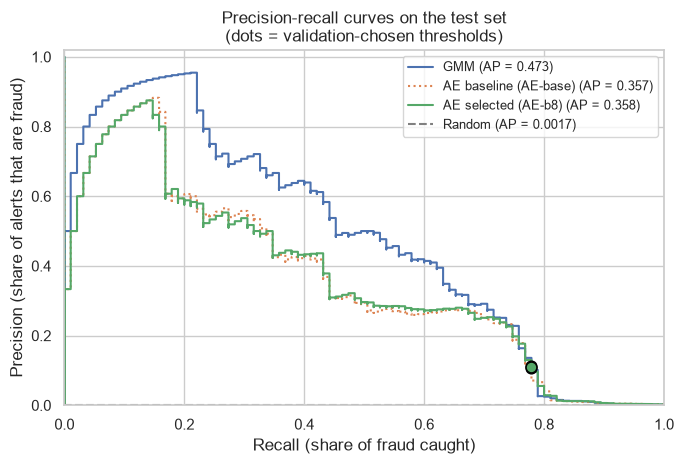

In [21]:
styles = {"GMM": "-", BASE_LABEL: ":", SELECTED_LABEL: "-"}
fig, ax = plt.subplots(figsize=(7, 4.8))
for name, scores in test_scores.items():
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap = average_precision_score(y_test, scores)
    line, = ax.step(recall, precision, where="post", ls=styles[name], label=f"{name} (AP = {ap:.3f})")
    # Mark the operating point chosen on validation
    m = metrics_at_threshold(y_test, scores, thresholds[name])
    ax.scatter(m["recall"], m["precision"], s=60, zorder=5, color=line.get_color(), edgecolor="black")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random (AP = {y_test.mean():.4f})")
ax.set_xlabel("Recall (share of fraud caught)")
ax.set_ylabel("Precision (share of alerts that are fraud)")
ax.set_title("Precision-recall curves on the test set\n(dots = validation-chosen thresholds)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### Operational trade-offs

The two plots answer two practical questions:

- **Left:** if we tolerate flagging some percentage of good customers (FPR), how much fraud do we catch?
- **Right:** if analysts can only review the top K alerts, what share of those alerts is real fraud, and what share of all fraud do they find?

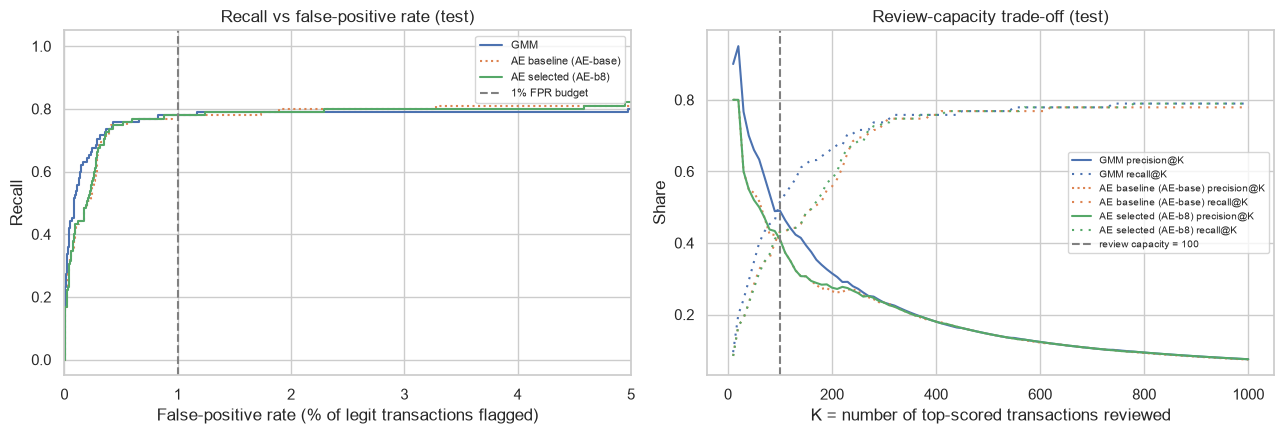

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: recall vs false-positive rate, zoomed in on the low-FPR region that matters in practice
for name, scores in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    axes[0].plot(fpr * 100, tpr, ls=styles[name], label=name)
axes[0].axvline(FPR_BUDGET * 100, ls="--", color="grey", label=f"{FPR_BUDGET:.0%} FPR budget")
axes[0].set_xlim(0, 5)
axes[0].set_xlabel("False-positive rate (% of legit transactions flagged)")
axes[0].set_ylabel("Recall")
axes[0].set_title("Recall vs false-positive rate (test)")
axes[0].legend(fontsize=8)

# Right: precision and recall among the top-K reviewed alerts
k_values = np.arange(10, 1001, 10)
for name, scores in test_scores.items():
    order = np.argsort(-scores, kind="stable")
    hits = np.cumsum(y_test[order])[k_values - 1]          # frauds found in the top K
    line, = axes[1].plot(k_values, hits / k_values, ls=styles[name], label=f"{name} precision@K")
    axes[1].plot(k_values, hits / y_test.sum(), ls=(0, (1, 3)), color=line.get_color(),
                 label=f"{name} recall@K")
axes[1].axvline(k_review, ls="--", color="grey", label=f"review capacity = {k_review}")
axes[1].set_xlabel("K = number of top-scored transactions reviewed")
axes[1].set_ylabel("Share")
axes[1].set_title("Review-capacity trade-off (test)")
axes[1].legend(fontsize=7)

plt.tight_layout()
plt.show()

### Do the models miss the same frauds?

We compare, fraud by fraud, which **test frauds each model misses** at its validation-chosen threshold. A shared miss is a fraud that gets `score <= threshold` from both models. This is checked directly here, not assumed.

In [23]:
fraud_idx = np.where(y_test == 1)[0]
missed = {name: set(fraud_idx[test_scores[name][fraud_idx] <= thresholds[name]]) for name in test_scores}


def overlap_row(first, second):
    return {"first model": first, "second model": second,
            "missed by first": len(missed[first]),
            "missed by second": len(missed[second]),
            "missed by both": len(missed[first] & missed[second]),
            "missed only by first": len(missed[first] - missed[second]),
            "missed only by second": len(missed[second] - missed[first])}


overlap = pd.DataFrame([overlap_row("GMM", SELECTED_LABEL), overlap_row(BASE_LABEL, SELECTED_LABEL)])
print(f"Test frauds: {len(fraud_idx)}")
print(f"Missed by ALL three models: {len(missed['GMM'] & missed[BASE_LABEL] & missed[SELECTED_LABEL])}")
overlap

Test frauds: 95
Missed by ALL three models: 20


,first model,second model,missed by first,missed by second,missed by both,missed only by first,missed only by second
0,GMM,AE selected (AE-b8),21,21,20,1,1
1,AE baseline (AE-base),AE selected (AE-b8),21,21,21,0,0


## G. Interpretation of the observed results

> The numbers below come from running this notebook with `SEED = 42` on the full `creditcard.csv`. The seeds are fixed, so a re-run should reproduce them. Small differences can appear across library versions or hardware. **Always quote the numbers your own run prints above.**

### Autoencoder experiments (decided on validation data only)

| Config | Bottleneck | Best early-stop MSE (epoch) | Stopped by | Validation AP |
|---|---|---|---|---|
| AE-base | 8 | 0.4353 (49 of 50) | epoch cap | 0.405 |
| **AE-b8** | 8 | 0.4256 (99 of 100) | epoch cap | **0.413** |
| AE-b4 | 4 | 0.5055 (100 of 100) | epoch cap | 0.377 |
| AE-b12 | 12 | 0.4023 (65 of 73) | early stopping | 0.282 |

**Experiment A: longer training.**

- With 100 epochs and patience 8, the reconstruction loss fell further (0.4353 → 0.4256).
- Validation AP rose only slightly (0.405 → 0.413, +0.008).
- The model again stopped at the epoch cap (best epoch 99). The loss was still creeping down, but the AP gain was so small that we did **not** extend training further.

**Experiment B: bottleneck size.**

- **b = 4** is too narrow. It cannot even rebuild legitimate transactions well (highest loss) and ranks fraud worse.
- **b = 12** gives the *lowest* reconstruction loss but by far the *worst* validation AP (0.282).
- A wide bottleneck lets the network copy almost any input, frauds included, so frauds stop standing out.
- **Lesson:** a lower reconstruction loss does not mean better fraud detection. That is why we selected on validation AP, not on loss.

**Selected configuration: `AE-b8`** (b = 8, 100 epochs, patience 8), chosen by the highest validation AP.

### Test results: the selected AE compared with the original baseline

| Metric (test) | AE baseline | AE selected (AE-b8) | Change |
|---|---|---|---|
| Average precision | 0.3568 | 0.3575 | +0.0007 |
| Precision @ top-100 | 0.41 | 0.41 | none |
| Recall @ validation threshold | 0.779 (74/95) | 0.779 (74/95) | none |
| Precision @ validation threshold | 0.112 | 0.111 | −0.001 |
| Test FPR @ validation threshold | 1.04% | 1.05% | +0.01 pp |
| Transactions flagged | 663 | 667 | +4 |

- The small validation gain **did not carry over to the test set**. Test performance is essentially unchanged.
- This is a normal and honest outcome: with 94 validation and 95 test frauds, a +0.008 AP difference is within noise.

### GMM compared with the autoencoder

**The GMM remains the stronger ranker.**

- It has the best AP on both validation (0.553) and test (0.473).
- Its precision@100 is 0.49 against 0.41 for both autoencoders.
- Its PR curve lies above both AE curves for recall up to about 0.75.
- In the recall-vs-FPR plot, it climbs fastest below about 0.5% FPR.

**At the 1% operating point, all three models are tied.**

- Each catches **74 of the 95** test frauds.
- Each flags about 660–690 transactions, so precision is only about 0.11, roughly 1 fraud per 9 alerts.
- The test FPR (1.04%–1.09%) is slightly above the 1% target. That is expected: a threshold set on one sample does not transfer exactly to another.

**The two "recall" numbers in the table are equal here, but only by coincidence.**

- *Recall @ 1% FPR (test ROC)* uses a cut-off derived from the test labels.
- *Recall @ val threshold* uses the threshold fixed on validation data.
- In this run both cut-offs happen to catch the same 74 frauds. They measure different things and would not always agree.

### Do the models miss the same frauds? (checked fraud by fraud)

- The GMM misses 21 test frauds and the selected AE misses 21.
- **20 of those are missed by both.** Each model catches exactly one fraud the other misses.
- The baseline AE and the selected AE miss exactly the same 21 frauds.
- 20 frauds are missed by all three models.

So yes, the models share almost all of their misses. About 21% of test frauds look like ordinary transactions in this feature space, so neither a density score nor a reconstruction score separates them.

### How much to trust these results

- The test set has only 95 frauds, so one fraud equals about 1 percentage point of recall.
- This is a single split with no confidence intervals.
- Differences of a few thousandths in AP, as between AE-base and AE-b8, are **not meaningful**.
- The GMM's lead of about 0.12 AP over the autoencoders is larger and consistent across validation and test, but it is still only suggestive.

## H. Conclusion and limitations

**What the experiment shows.**

- Two models trained *only* on legitimate transactions, with no fraud labels in training, rank fraud far above chance.
- At a 1% false-positive budget fixed on validation data, both catch about three-quarters of the test frauds.
- A simple density model (GMM) was at least as good as a small neural autoencoder on this data.
- Tuning the autoencoder on validation data improved its validation AP slightly. Longer training gave 0.405 → 0.413, and the best bottleneck was b = 8.
- That gain did **not** show up on the test set (test AP 0.357 → 0.358), and it did not close the gap to the GMM.
- A lower reconstruction loss (b = 12) actually made fraud ranking **worse**.

**Strengths and weaknesses**

| | GMM | Autoencoder |
|---|---|---|
| Strengths | Clear probabilistic meaning (a log-likelihood); few settings to choose; fast; model size chosen objectively with BIC | Learns non-linear structure; scales well to many features and rows; no Gaussian assumption |
| Weaknesses | Assumes the data is a mix of Gaussian blobs; ~465 parameters per component in 29-D; can collapse onto near-singular components without regularisation; BIC choice depends on the subsample and on `reg_covar` | More choices (bottleneck size, epochs, learning rate); the bottleneck size strongly affects results (validation AP 0.28–0.41); the error is a distance, not a probability; a too-wide bottleneck also rebuilds frauds well |

**Effect of extreme class imbalance.**

- With only 0.17% fraud, even a 1% FPR means about 570 false alarms per ~57k transactions, which outnumber the ~95 frauds.
- That is why precision at the threshold is only about 0.11 although recall is about 0.78.
- Accuracy would be above 98% for either model and would hide all of this.

**Anomaly scores are not fraud probabilities.**

- A negative log-likelihood of 60, or a reconstruction error of 2, does not mean "60%" or "2%" chance of fraud.
- The scores only *rank* transactions, and they are on different scales for the two models.
- Turning them into calibrated probabilities would need labelled data and a calibration step, such as Platt scaling or isotonic regression.
- Also, "unusual" is not the same as "fraudulent". Rare but legitimate behaviour is flagged too.

**Limitations**

- **Unsupervised by design.** The 284 fraud labels in the training split are thrown away, even though a supervised model could use them.
- **Anonymised PCA features.** We cannot interpret `V1`–`V28`, engineer domain features, or check *why* a transaction was flagged.
  - The PCA was fitted by the data provider on the whole dataset, so the features already carry information from every row. We cannot undo this.
- **Random split.** The data covers only two days, so this experiment does not test performance on *future* transactions, where fraud patterns drift.
- **A single run.** One seed and one split, with no confidence intervals. The test set has only 95 frauds.
- **Simple settings.** Only a few GMM sizes and three AE bottleneck sizes were tried. `AE-b8` still stopped at its 100-epoch cap with the loss falling slowly. Given the tiny AP gain from 50 to 100 epochs, we did not extend training further.
- **Validation reuse.** The validation set was used both to pick the AE configuration and to set thresholds. With four candidate configurations this optimism is small, but the validation AP of the chosen model is slightly flattering.

**Possible future improvements** (not implemented)

- Use repeated or bootstrapped splits to get confidence intervals for AP and recall.
- Make a chronological train/test split, and turn `Time` into an hour-of-day feature.
- Try other GMM covariance types (`diag`, `tied`), a wider K range, or other `reg_covar` values.
- Tune the autoencoder further (depth, dropout, learning-rate schedule), ideally with repeated splits so that small differences can be told apart from noise. Or try a variational autoencoder.
- Combine the two scores, for example by averaging their rank percentiles.
- Compare with other unsupervised baselines such as Isolation Forest or One-Class SVM.
- Use the available fraud labels in a semi-supervised or supervised model, and calibrate its probabilities.